# this notebook analyzes OxfordIIITPet dataset for model training 

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import importlib
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision import datasets
from torchvision.utils import make_grid
from pet_breed_classifier.data import get_dataloaders
from pet_breed_classifier import visualize

In [2]:
root = Path("../data").resolve()

## image sizes and ration statistics
images vary in sizes so taking 224x224 sized crops will be usefull for training, also pretrained model i am going to use is trained on this kind of data

             width       height        ratio
count  3680.000000  3680.000000  3680.000000
mean    431.033424   383.420380     0.934880
std     126.328303   116.833678     0.315808
min     114.000000   108.000000     0.390000
25%     333.000000   333.000000     0.684000
50%     500.000000   375.000000     0.750000
75%     500.000000   500.000000     1.278772
max    3264.000000  2606.000000     1.937984


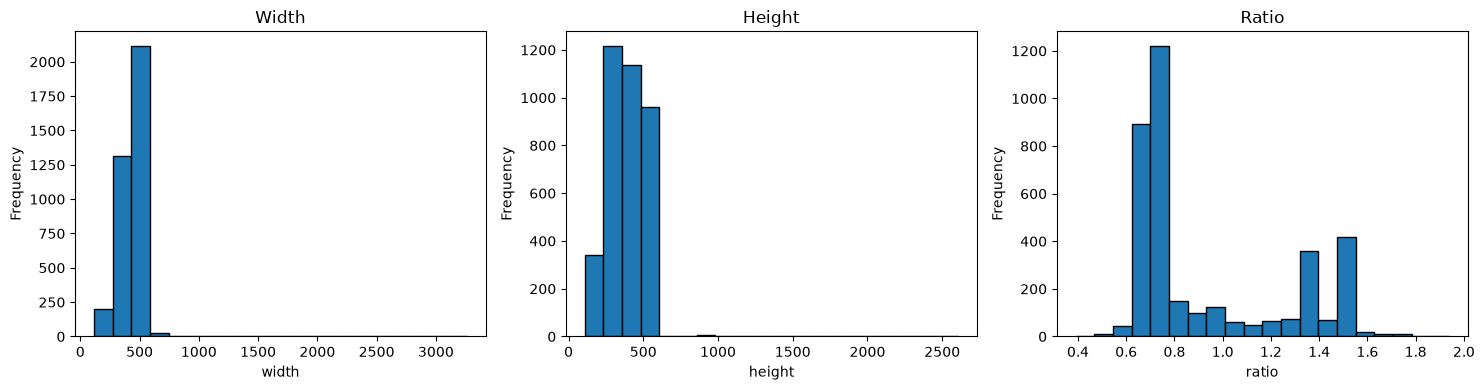

In [3]:
raw = datasets.OxfordIIITPet(root, split="trainval")

width_ar = np.zeros(len(raw))
height_ar =  np.zeros(len(raw))

for i in range(len(raw)):
    img, label = raw[i]
    width_ar[i] = img.size[0]
    height_ar[i] = img.size[1]
    
aspect_ratio = height_ar/width_ar
raw_df = pd.DataFrame({"width":width_ar,
                       "height":height_ar,
                       "ratio": aspect_ratio})
print(raw_df.describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, raw_df.columns):
    ax.hist(raw_df[column], bins=20, edgecolor="black")
    ax.set_title(column.capitalize())
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## similar breeds analysis
as we can see breeds can be similar in appearance and we can expect confusion from model between pairs like this

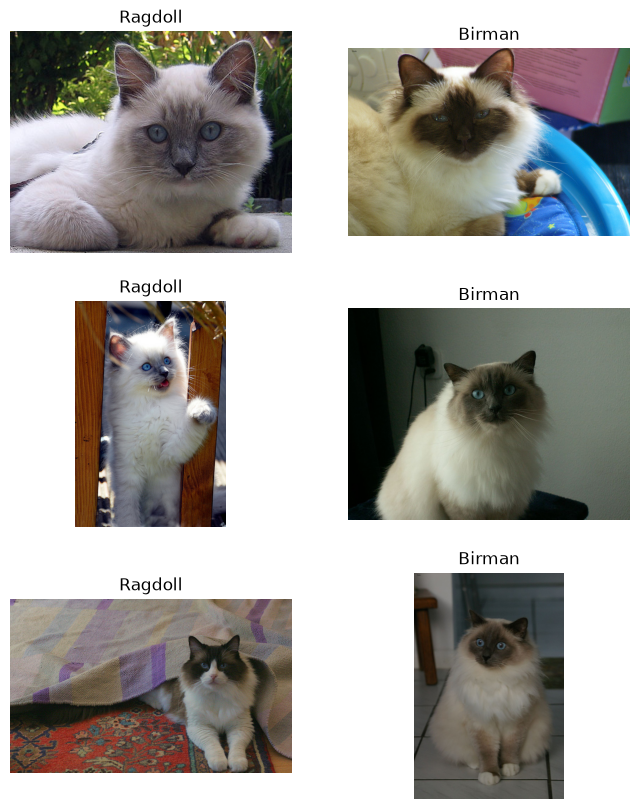

In [4]:
ragdoll_idx = raw.class_to_idx["Ragdoll"]
birman_idx = raw.class_to_idx["Birman"]

ragdoll, birman = [], []

for img, label in raw:
    if label == ragdoll_idx and len(ragdoll) < 3:
        ragdoll.append((img, label))
    elif label == birman_idx and len(birman) < 3:
        birman.append((img, label))

    if len(ragdoll) == 3 and len(birman) == 3:
        break
        
fig, ax = plt.subplots(3, 2, figsize=(8, 10))
for i in range(3):
    ax[i, 0].imshow(ragdoll[i][0])
    ax[i, 0].set_title("Ragdoll")
    ax[i, 0].axis("off")

    ax[i, 1].imshow(birman[i][0])
    ax[i, 1].set_title("Birman")
    ax[i, 1].axis("off")

In [5]:
train_loader, val_loader, test_loader, classes = get_dataloaders(root)

## data distribution
we have 37 different breeds: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']

data is distributed as follows: train dataset - 2944 examples, validation - 736 examples, test - 3669 examples

In [6]:
print(len(train_loader.dataset))
print(len(val_loader.dataset))
print(len(test_loader.dataset))
print(len(classes))
print(classes)

2944
736
3669
37
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


## training set distribution 
training dataset is class balanced, so accuracy will be reasonable measure

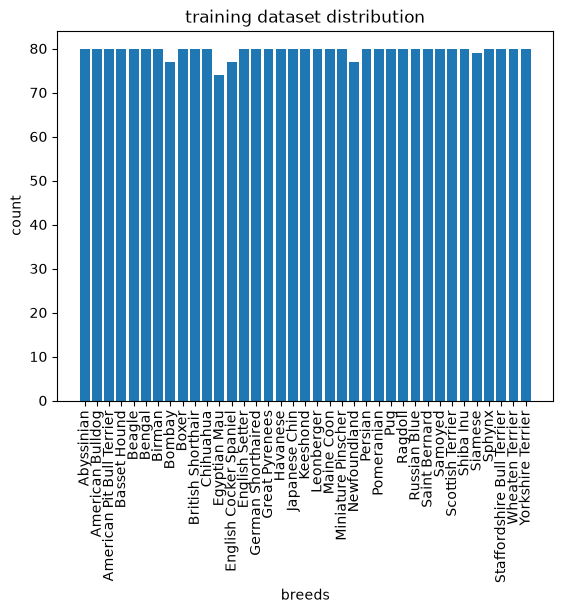

In [7]:
labels = np.array(train_loader.dataset.dataset._labels)
bins = np.bincount(labels[train_loader.dataset.indices.tolist()])
fig, ax = plt.subplots()
ax.bar(train_loader.dataset.dataset.classes, bins)
ax.tick_params(axis="x", labelrotation=90)
ax.set_title("training dataset distribution")
ax.set_xlabel("breeds")
ax.set_ylabel("count")
plt.show()

## validation set distribution
data is also class balanced in validation dataset, every class is eqally represented. so train_test_split with stratify worked well.

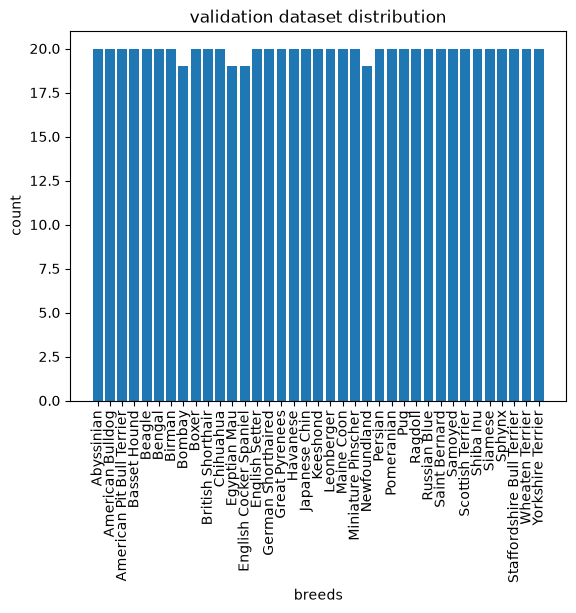

In [8]:
val_bins = np.bincount(labels[val_loader.dataset.indices.tolist()])

fig, ax = plt.subplots()
ax.bar(train_loader.dataset.dataset.classes, val_bins)
ax.tick_params(axis="x", labelrotation=90)
ax.set_title("validation dataset distribution")
ax.set_xlabel("breeds")
ax.set_ylabel("count")
plt.show()

## overview of our dataset

when we  crop part of image we must be sure that pet will be mostly kept in resulting image, otherwise model might find it difficult to differentiate them, so ensuring that every crop contains at least 60% of the image would be good decision in our case

['Pug', 'Yorkshire Terrier', 'British Shorthair', 'Chihuahua', 'English Cocker Spaniel', 'Saint Bernard', 'Egyptian Mau', 'Egyptian Mau', 'Staffordshire Bull Terrier', 'Bombay', 'Ragdoll', 'Sphynx', 'Beagle', 'Keeshond', 'Miniature Pinscher', 'Scottish Terrier', 'English Cocker Spaniel', 'Great Pyrenees', 'English Setter', 'Maine Coon', 'Bombay', 'Bombay', 'Samoyed', 'Saint Bernard', 'English Cocker Spaniel', 'Newfoundland', 'American Pit Bull Terrier', 'Maine Coon', 'Staffordshire Bull Terrier', 'Maine Coon', 'Pug', 'Bombay']


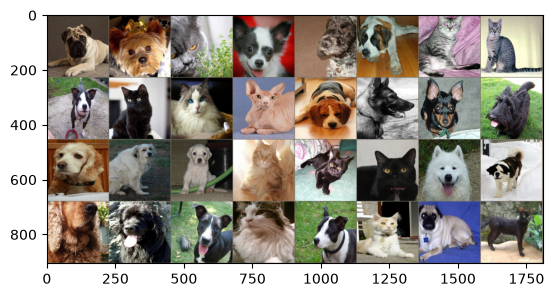

In [9]:
batch_images, batch_labels = next(iter(train_loader))

dataset = train_loader.dataset.dataset
batch_classes = [dataset.classes[i] for i in batch_labels]
print(batch_classes)
batch_image = make_grid(batch_images)
visualize.imshow(batch_image)